# Fase 2. Comprension de los datos

**Proyecto:** Prediccion de CTR en anuncios digitales  
**Metodologia:** CRISP-DM  
**Dataset:** Criteo Attribution Modeling (`pcb_dataset_final.tsv`)

## Proposito

En esta fase se recopilan, describen y exploran los datos para conocer su estructura, calidad, distribucion y posibles limitaciones antes de transformarlos. El objetivo del proyecto es predecir `click` (0 = sin clic, 1 = clic) con informacion disponible al momento de la impresion.

**Fuente:** [Criteo Attribution Modeling en Kaggle](https://www.kaggle.com/datasets/sharatsachin/criteo-attribution-modeling).

> Este notebook documenta la comprension y exploracion. La limpieza, transformacion, seleccion definitiva de variables y particion entrenamiento/validacion/prueba pertenecen a la Fase 3.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 30)
sns.set_theme(style="whitegrid")

NOMBRE_ARCHIVO = "pcb_dataset_final.tsv"
RUTAS_CANDIDATAS = [
    Path.cwd() / "data" / "raw" / NOMBRE_ARCHIVO,
    Path.cwd().parent / "data" / "raw" / NOMBRE_ARCHIVO,
]
DATA_PATH = next((ruta.resolve() for ruta in RUTAS_CANDIDATAS if ruta.is_file()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"No se encontro {NOMBRE_ARCHIVO}. Se busco en: "
        + ", ".join(str(ruta) for ruta in RUTAS_CANDIDATAS)
    )

PROJECT_ROOT = DATA_PATH.parents[2]
TEMP_DIR = PROJECT_ROOT / "data" / "temp_duckdb"
TEMP_DIR.mkdir(parents=True, exist_ok=True)

print(f"Archivo: {DATA_PATH}")
print(f"Tamano: {DATA_PATH.stat().st_size / (1024 ** 3):.2f} GiB")
print("Formato: TSV separado por tabulaciones")

Archivo: C:\Users\Valentina\Documents\Mineria de datos\proyecto-prediccion-ctr\data\raw\pcb_dataset_final.tsv
Tamano: 2.41 GiB
Formato: TSV separado por tabulaciones


## 1. Inspeccion inicial y estructura

Se leen las primeras 1.000 filas para revisar columnas, tipos inferidos, ejemplos y dimensiones sin cargar el archivo completo en memoria. Esta lectura **no** es aleatoria; por eso no se usa para inferir por si sola el comportamiento de toda la poblacion.

In [2]:
COLUMNAS_ESPERADAS = [
    "timestamp", "uid", "campaign", "conversion", "conversion_timestamp",
    "conversion_id", "attribution", "click", "click_pos", "click_nb",
    "cost", "cpo", "time_since_last_click", "cat1", "cat2", "cat3",
    "cat4", "cat5", "cat6", "cat7", "cat8", "cat9",
]

TAMANO_MUESTRA = 1_000
df_muestra = pd.read_csv(DATA_PATH, sep="\t", nrows=TAMANO_MUESTRA)

if df_muestra.columns.tolist() != COLUMNAS_ESPERADAS:
    raise ValueError(
        "El esquema del archivo no coincide con las 22 columnas esperadas. "
        f"Columnas encontradas: {df_muestra.columns.tolist()}"
    )

print(f"Filas cargadas en la muestra: {len(df_muestra):,}")
print(f"Columnas: {df_muestra.shape[1]}")
df_muestra.info()

Filas cargadas en la muestra: 1,000
Columnas: 22
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   timestamp              1000 non-null   int64  
 1   uid                    1000 non-null   int64  
 2   campaign               1000 non-null   int64  
 3   conversion             1000 non-null   int64  
 4   conversion_timestamp   1000 non-null   int64  
 5   conversion_id          1000 non-null   int64  
 6   attribution            1000 non-null   int64  
 7   click                  1000 non-null   int64  
 8   click_pos              1000 non-null   int64  
 9   click_nb               1000 non-null   int64  
 10  cost                   1000 non-null   float64
 11  cpo                    1000 non-null   float64
 12  time_since_last_click  1000 non-null   int64  
 13  cat1                   1000 non-null   int64  
 14  cat2               

In [3]:
display(df_muestra.head(10))

,timestamp,uid,campaign,conversion,conversion_timestamp,conversion_id,attribution,click,click_pos,click_nb,cost,cpo,time_since_last_click,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9
0,0,20073966,22589171,0,-1,-1,0,0,-1,-1,0.000010,0.390794,-1,5824233,9312274,3490278,29196072,11409686,1973606,25162884,29196072,29196072
1,2,24607497,884761,0,-1,-1,0,0,-1,-1,0.000010,0.059600,423858,30763035,9312274,14584482,29196072,11409686,1973606,22644417,9312274,21091111
2,2,28474333,18975823,0,-1,-1,0,0,-1,-1,0.000183,0.149706,8879,138937,9312274,10769841,29196072,5824237,138937,1795451,29196072,15351056
3,3,7306395,29427842,1,1449193,3063962,0,1,0,7,0.000094,0.154785,-1,28928366,26597095,12435261,23549932,5824237,1973606,9180723,29841067,29196072
4,3,25357769,13365547,0,-1,-1,0,0,-1,-1,0.000032,0.037583,-1,138937,26597094,31616034,29196072,11409684,26597096,4480345,29196072,29196072
5,4,93907,17686799,0,-1,-1,0,1,-1,-1,0.000186,0.267100,262565,30763035,9068207,9107790,29196072,32440044,1973606,2687461,29841067,21091108
6,4,19923387,31772643,0,-1,-1,0,0,-1,-1,0.000035,0.087070,179666,30763035,9312274,5028397,29196072,32440044,32440041,14074087,29196072,21091108
7,4,28451570,20843295,0,-1,-1,0,0,-1,-1,0.000035,0.336611,-1,138937,9312274,15403272,29196072,32440042,28928366,8556462,29196072,29196072
8,7,5588915,27491436,0,-1,-1,0,0,-1,-1,0.000074,0.216361,-1,138937,9312274,4281154,29196072,28928366,29196072,21857352,29196072,29196072
9,7,23074162,16184517,0,-1,-1,0,0,-1,-1,0.000013,0.004107,-1,28928366,26597095,7711526,29196072,3225250,1973606,17737135,9312274,29196072


## 2. Clasificacion semantica de variables

Los campos `cat1` a `cat9` son codigos categoricos anonimizados: que el archivo los almacene como numeros no significa que sean magnitudes. Los identificadores tampoco deben tratarse automaticamente como variables numericas continuas.

In [4]:
variables_identificadoras = ["uid", "campaign", "conversion_id"]
variables_temporales = ["timestamp", "conversion_timestamp"]
variables_binarias = ["conversion", "attribution"]
variables_categoricas = [f"cat{i}" for i in range(1, 10)]
variables_numericas = [
    "cost", "cpo", "time_since_last_click", "click_pos", "click_nb"
]
variable_objetivo = "click"

roles = {}
for columna in variables_identificadoras:
    roles[columna] = "Identificador"
for columna in variables_temporales:
    roles[columna] = "Temporal"
for columna in variables_binarias:
    roles[columna] = "Binaria / resultado de atribucion"
for columna in variables_categoricas:
    roles[columna] = "Categorica anonimizada"
for columna in variables_numericas:
    roles[columna] = "Numerica"
roles[variable_objetivo] = "Objetivo"

if set(roles) != set(df_muestra.columns):
    raise ValueError("La clasificacion semantica no cubre exactamente el esquema leido.")

tabla_variables = pd.DataFrame({
    "Variable": df_muestra.columns,
    "Tipo inferido por pandas": [str(df_muestra[col].dtype) for col in df_muestra.columns],
    "Clasificacion semantica": [roles[col] for col in df_muestra.columns],
    "Valores unicos en muestra": [df_muestra[col].nunique(dropna=False) for col in df_muestra.columns],
})
display(tabla_variables)

,Variable,Tipo inferido por pandas,Clasificacion semantica,Valores unicos en muestra
0,timestamp,int64,Temporal,509
1,uid,int64,Identificador,922
2,campaign,int64,Identificador,297
3,conversion,int64,Binaria / resultado de atribucion,2
4,conversion_timestamp,int64,Temporal,41
5,conversion_id,int64,Identificador,41
6,attribution,int64,Binaria / resultado de atribucion,2
7,click,int64,Objetivo,2
8,click_pos,int64,Numerica,11
9,click_nb,int64,Numerica,12


## 3. Calidad de la muestra

Se revisan valores nulos y el valor `-1` en las primeras filas. En este dataset `-1` puede representar que un dato no aplica o no esta disponible; no se asume que signifique lo mismo en todas las columnas.

In [5]:
calidad_muestra = pd.DataFrame({
    "Nulos": df_muestra.isna().sum(),
    "Nulos (%)": df_muestra.isna().mean().mul(100),
    "Valores -1": df_muestra.eq(-1).sum(),
    "Valores -1 (%)": df_muestra.eq(-1).mean().mul(100),
})
display(calidad_muestra)

,Nulos,Nulos (%),Valores -1,Valores -1 (%)
timestamp,0,0.0,0,0.0
uid,0,0.0,0,0.0
campaign,0,0.0,0,0.0
conversion,0,0.0,0,0.0
conversion_timestamp,0,0.0,956,95.6
conversion_id,0,0.0,956,95.6
attribution,0,0.0,0,0.0
click,0,0.0,0,0.0
click_pos,0,0.0,956,95.6
click_nb,0,0.0,956,95.6


## 4. Variable objetivo: `click` (muestra)

La siguiente distribucion corresponde nicamente a la muestra inicial de 1.000 filas. La proporcion final de clases se calculara de nuevo sobre todo el archivo.

,Registros,Porcentaje (%)
click,,
0,649,64.9
1,351,35.1


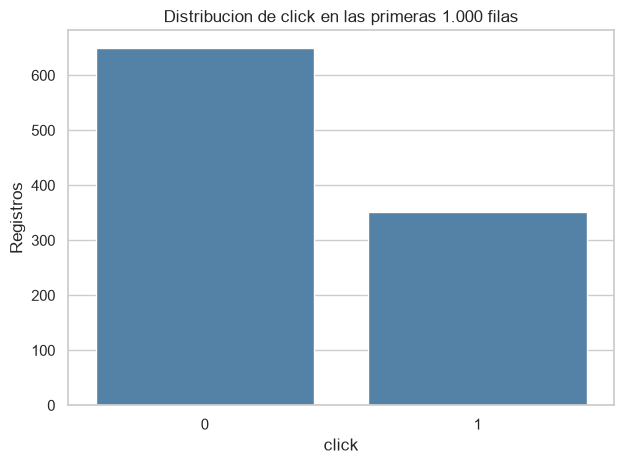

In [6]:
distribucion_click_muestra = (
    df_muestra["click"].value_counts(dropna=False).sort_index().rename("Registros").to_frame()
)
distribucion_click_muestra["Porcentaje (%)"] = (
    distribucion_click_muestra["Registros"] / len(df_muestra) * 100
)
display(distribucion_click_muestra)

ax = sns.countplot(data=df_muestra, x="click", order=[0, 1], color="steelblue")
ax.set(title="Distribucion de click en las primeras 1.000 filas", xlabel="click", ylabel="Registros")
plt.tight_layout()
plt.show()

## 5. Exploracion de variables categoricas (muestra)

Se resumen la cardinalidad y la participacion de la categoria mas frecuente en cada campo `cat`. Estos valores describen solo las primeras 1.000 filas; no representan la cardinalidad exacta de todo el dataset.

,Categorias observadas,Categoria mas frecuente (%)
cat1,9,40.6
cat2,34,47.2
cat3,439,3.0
cat4,8,86.7
cat5,37,26.4
cat6,22,42.2
cat7,523,12.8
cat8,11,60.8
cat9,27,53.0


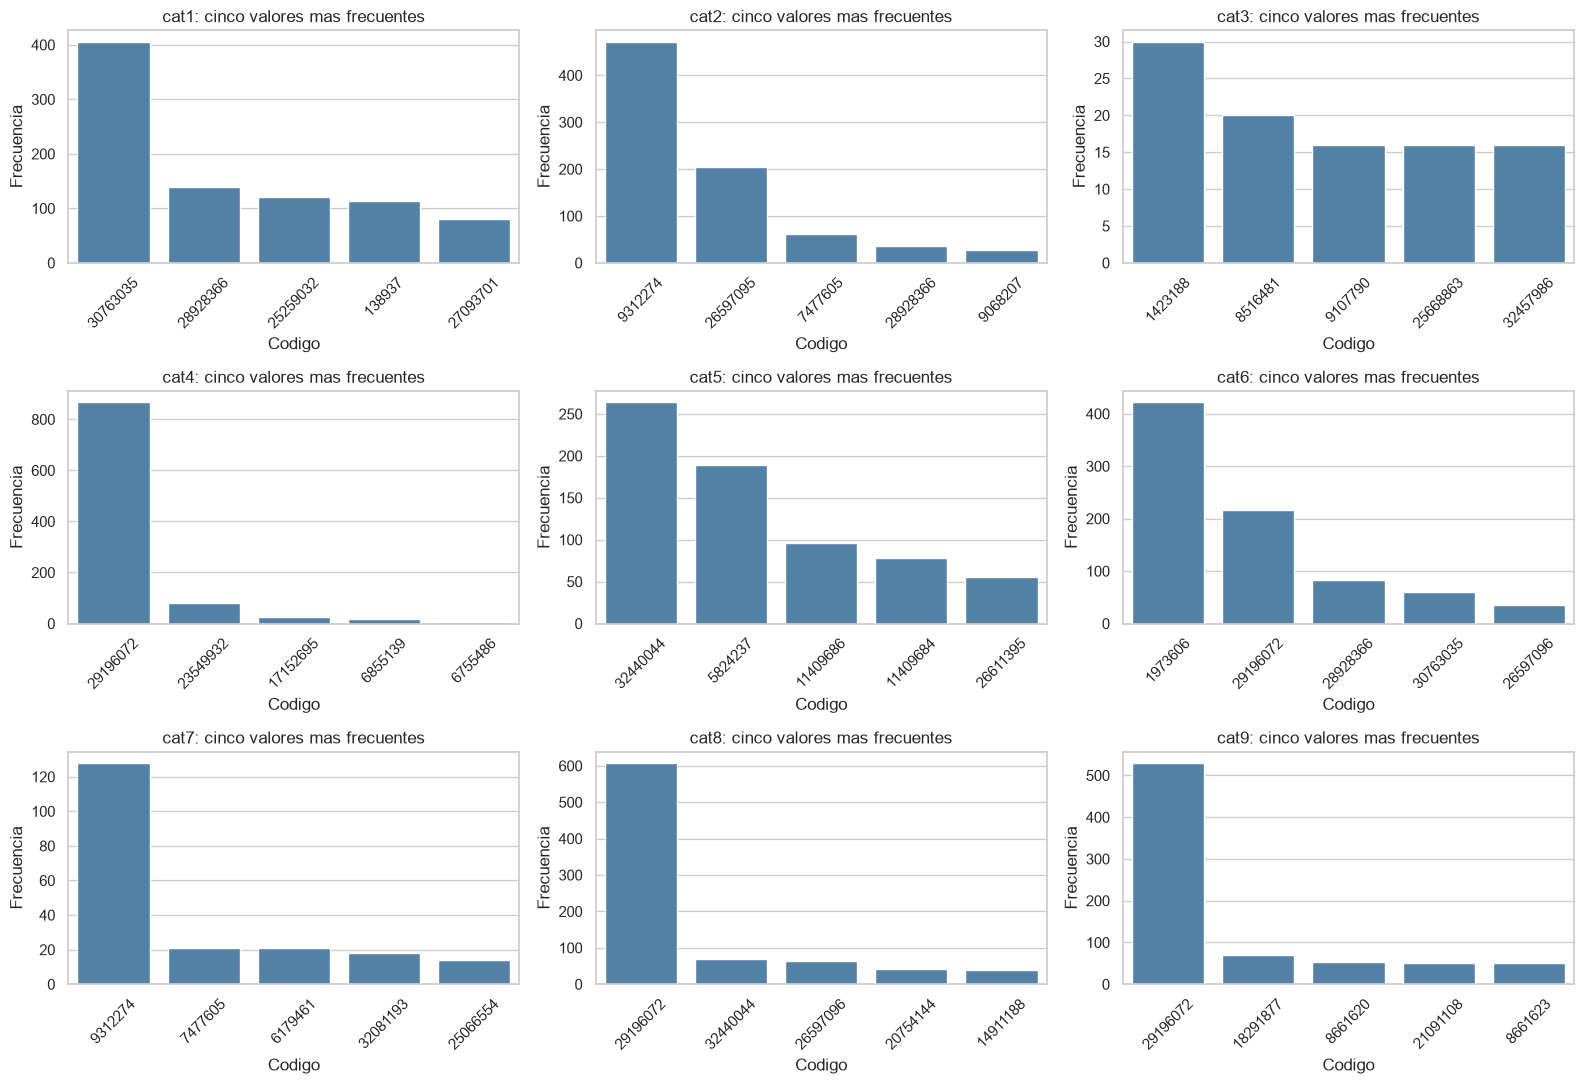

In [7]:
perfil_categorico_muestra = pd.DataFrame(index=variables_categoricas)
perfil_categorico_muestra["Categorias observadas"] = [
    df_muestra[col].nunique(dropna=False) for col in variables_categoricas
]
perfil_categorico_muestra["Categoria mas frecuente (%)"] = [
    df_muestra[col].value_counts(normalize=True, dropna=False).iloc[0] * 100
    for col in variables_categoricas
]
display(perfil_categorico_muestra)

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for columna, ax in zip(variables_categoricas, axes.flat):
    frecuencias = df_muestra[columna].value_counts().head(5)
    sns.barplot(x=frecuencias.index.astype(str), y=frecuencias.values, ax=ax, color="steelblue")
    ax.set_title(f"{columna}: cinco valores mas frecuentes")
    ax.set_xlabel("Codigo")
    ax.set_ylabel("Frecuencia")
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

## 6. Exploracion de variables numericas (muestra)

Las estadisticas y graficos excluyen temporalmente `-1` solo para facilitar la inspeccion visual; esto no modifica el dataset ni establece el tratamiento que se aplicara en la Fase 3.

,count,mean,std,min,25%,50%,75%,max
cost,1000.0,0.000264,0.000733,0.00001,0.000019,0.000069,0.000199,1.062734e-02
cpo,1000.0,0.181107,0.123963,0.00400,0.080498,0.177785,0.262916,6.610908e-01
time_since_last_click,470.0,581087.555319,655766.822754,1.00000,59125.750000,288420.500000,951504.500000,2.413747e+06
click_pos,44.0,2.000000,4.017404,0.00000,0.000000,1.000000,2.000000,1.800000e+01
click_nb,44.0,4.295455,4.693288,1.00000,1.750000,3.000000,5.000000,2.000000e+01


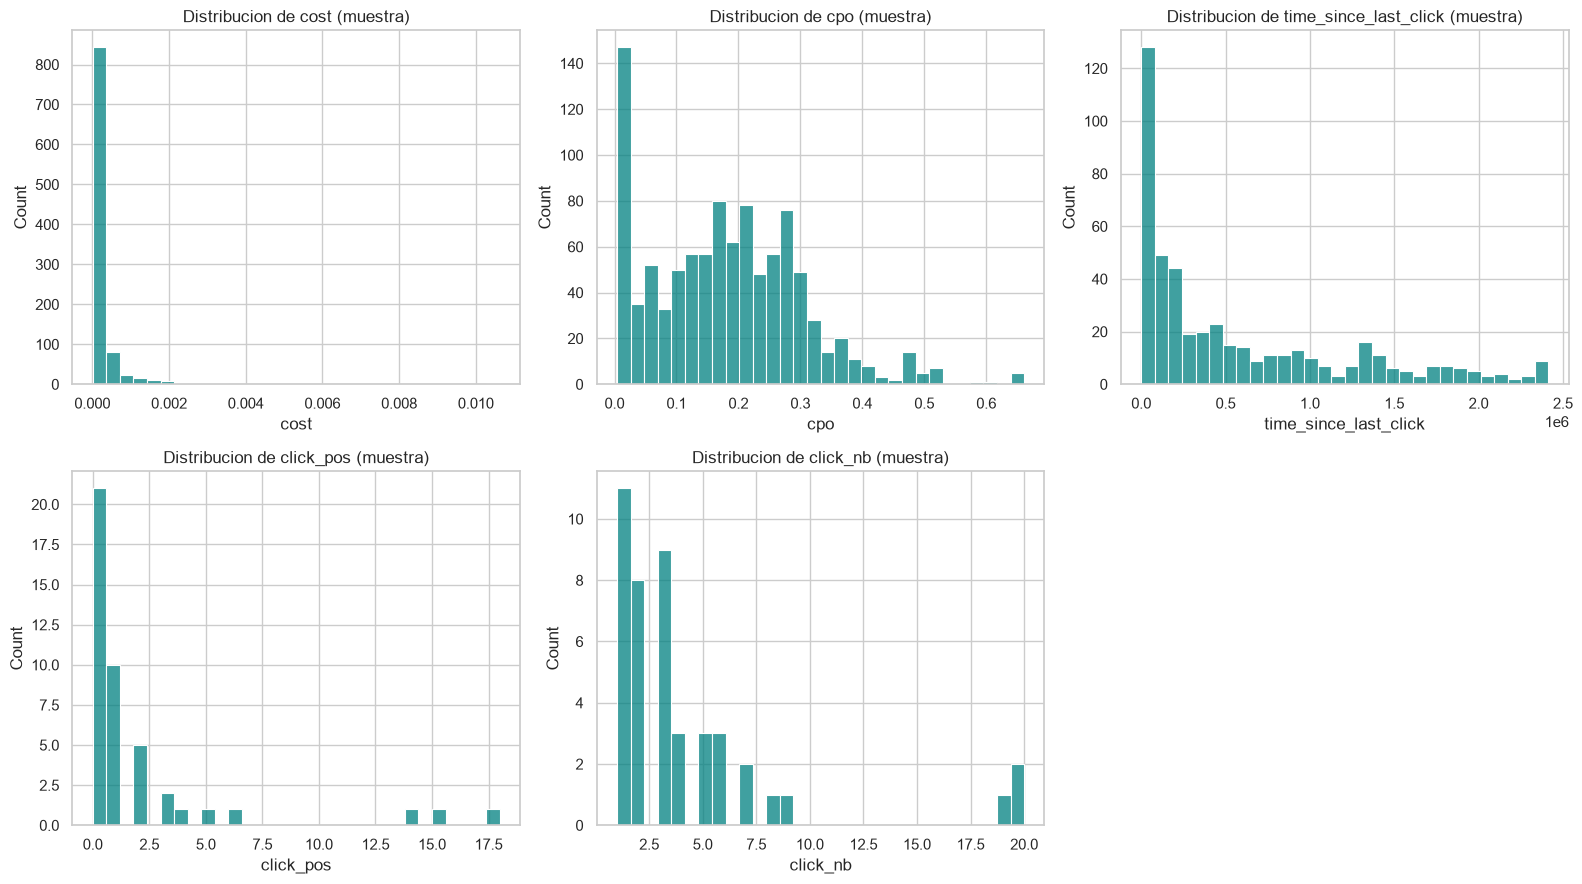

In [8]:
muestra_numerica = df_muestra[variables_numericas].replace(-1, np.nan)
display(muestra_numerica.describe().T)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for columna, ax in zip(variables_numericas, axes.flat):
    valores = muestra_numerica[columna].dropna()
    if valores.empty:
        ax.set_title(f"{columna}: sin valores distintos de -1 en la muestra")
        ax.set_axis_off()
    else:
        sns.histplot(valores, ax=ax, bins=30, color="teal")
        ax.set_title(f"Distribucion de {columna} (muestra)")
        ax.set_xlabel(columna)
fig.delaxes(axes.flat[-1])
fig.tight_layout()
plt.show()

## 7. Relacion entre clic y conversion (muestra)

La tabla es descriptiva y corresponde nicamente a la muestra. Una conversion es un resultado posterior a la impresion; su relacion con `click` no demuestra causalidad y advierte que las variables de conversion deben excluirse o justificarse antes de entrenar un modelo de CTR.

In [9]:
tabla_click_conversion_muestra = pd.crosstab(
    df_muestra["click"],
    df_muestra["conversion"],
    normalize="index",
    dropna=False,
).mul(100)
tabla_click_conversion_muestra.index.name = "click"
tabla_click_conversion_muestra.columns.name = "conversion (%)"
display(tabla_click_conversion_muestra)

conversion (%),0,1
click,,
0,100.000000,0.000000
1,87.464387,12.535613


## 8. Perfil de calidad y objetivo (dataset completo)

Por el tamano del archivo, se recorre en bloques de 500.000 filas. En esta pasada se calculan el numero de registros, valores nulos, valores `-1` y distribucion de `click` para el **conjunto completo**, sin guardar el dataset completo en memoria.

In [10]:
TAMANO_BLOQUE = 500_000
total_filas = 0
nulos_globales = pd.Series(0, index=COLUMNAS_ESPERADAS, dtype="int64")
menos_uno_global = pd.Series(0, index=COLUMNAS_ESPERADAS, dtype="int64")
conteo_click_global = {0: 0, 1: 0}
valores_click_no_binarios = 0

for bloque in pd.read_csv(DATA_PATH, sep="\t", chunksize=TAMANO_BLOQUE, low_memory=False):
    total_filas += len(bloque)
    nulos_globales += bloque.isna().sum().astype("int64")
    menos_uno_global += bloque.eq(-1).sum().astype("int64")
    conteo_click_global[0] += int(bloque["click"].eq(0).sum())
    conteo_click_global[1] += int(bloque["click"].eq(1).sum())
    valores_click_no_binarios += int((~bloque["click"].isin([0, 1])).sum())

if total_filas == 0:
    raise ValueError("El archivo no contiene registros.")

print(f"Registros procesados: {total_filas:,}")
print(f"Columnas: {len(COLUMNAS_ESPERADAS)}")
print(f"Valores de click distintos de 0/1 (incluye nulos): {valores_click_no_binarios:,}")

calidad_global = pd.DataFrame({
    "Valores nulos": nulos_globales,
    "Nulos (%)": nulos_globales.div(total_filas).mul(100),
    "Valores -1": menos_uno_global,
    "Valores -1 (%)": menos_uno_global.div(total_filas).mul(100),
})
print("Calidad global por columna:")
display(calidad_global)

click_global = pd.DataFrame.from_dict(conteo_click_global, orient="index", columns=["Registros"])
click_global.index.name = "click"
click_global["Porcentaje (%)"] = click_global["Registros"].div(total_filas).mul(100)
print("Distribucion global de click:")
display(click_global)

Registros procesados: 16,468,027
Columnas: 22
Valores de click distintos de 0/1 (incluye nulos): 0
Calidad global por columna:


,Valores nulos,Nulos (%),Valores -1,Valores -1 (%)
timestamp,0,0.0,0,0.000000
uid,0,0.0,0,0.000000
campaign,0,0.0,0,0.000000
conversion,0,0.0,0,0.000000
conversion_timestamp,0,0.0,15661831,95.104477
conversion_id,0,0.0,15661831,95.104477
attribution,0,0.0,0,0.000000
click,0,0.0,0,0.000000
click_pos,0,0.0,15661831,95.104477
click_nb,0,0.0,15661831,95.104477


Distribucion global de click:


,Registros,Porcentaje (%)
click,,
0,10520464,63.88418
1,5947563,36.11582


Revisa las tablas globales: verifica si hay nulos, en que columnas aparece -1 y con que frecuencia, y confirma que esten presentes ambas clases de click. El valor -1 debe interpretarse segun la semantica de cada variable; no se debe imputar o eliminar de forma uniforme.

## 9. Duplicados exactos (dataset completo)

DuckDB compara todas las columnas del TSV y cuenta cuantas filas exceden la primera aparicion de cada registro identico. La ejecucion puede tardar y usar espacio temporal en `data/temp_duckdb`. Este control es global, a diferencia del chequeo de duplicados de la muestra.

In [11]:
conexion = duckdb.connect(config={"temp_directory": str(TEMP_DIR)})
try:
    duplicados_globales = conexion.execute(
        """
        SELECT COALESCE(SUM(repeticiones - 1), 0)
        FROM (
            SELECT *, COUNT(*) AS repeticiones
            FROM read_csv(?, delim='\t', header=true, all_varchar=true)
            GROUP BY ALL
            HAVING COUNT(*) > 1
        )
        """,
        [str(DATA_PATH)],
    ).fetchone()[0]
finally:
    conexion.close()

print(f"Registros duplicados exactos en todo el dataset: {int(duplicados_globales):,}")
print(f"Porcentaje de duplicados: {duplicados_globales / total_filas * 100:.6f}%")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Registros duplicados exactos en todo el dataset: 0
Porcentaje de duplicados: 0.000000%


## 10. Variables candidatas y riesgo de fuga de informacion

El momento de prediccion es la impresion del anuncio. Antes de entrenar, debe verificarse que cada caracteristica esta disponible en ese momento; una variable que se calcule despues del clic puede revelar indirectamente la respuesta.

| Grupo | Variables | Consideracion inicial |
|---|---|---|
| Objetivo | `click` | Es la etiqueta a predecir; nunca debe incluirse como predictor. |
| Excluir inicialmente | `conversion`, `conversion_timestamp`, `conversion_id`, `attribution`, `click_pos`, `click_nb`, `cpo` | Describen conversion, atribucion, clic o pedido; pueden contener informacion posterior al momento de prediccion. |
| Evaluar disponibilidad y codificacion | `uid`, `campaign`, `cost`, `timestamp`, `time_since_last_click` | Verificar disponibilidad temporal, utilidad, cardinalidad y riesgo de memorizar usuarios/campanas. |
| Candidatas contextuales | `cat1` a `cat9` | Codigos categoricos anonimizados; evaluar representacion y cardinalidad en la Fase 3. |

Esta es una seleccion preliminar, no una lista final de caracteristicas. La decision debe documentarse en la Fase 3 con base en el momento real en que se genera cada campo.

## 11. Conclusiones de la Fase 2 y entrega a Fase 3

Al terminar de ejecutar el notebook, registrar y confirmar:

- **Estructura:** numero global de filas y 22 columnas.
- **Calidad:** nulos, valores `-1` y duplicados exactos segun las celdas globales.
- **Objetivo:** cantidades y porcentajes globales de `click = 0` y `click = 1`.
- **Exploracion:** patrones visibles en la muestra, manteniendo explicito que son orientativos y no necesariamente representativos.
- **Riesgos:** variables derivadas de resultados posteriores y posibles identificadores con alta cardinalidad.

### Decisiones que quedan para la Fase 3

1. Definir el tratamiento de `-1` variable por variable, sin asumir que todos representan lo mismo.
2. Excluir variables que revelen resultados posteriores y documentar la disponibilidad temporal de las variables dudosas.
3. Preparar tipos y codificacion eficientes para los modelos, especialmente para `cat1``cat9` y variables de alta cardinalidad.
4. Construir y guardar el dataset procesado.
5. Crear particiones de entrenamiento, validacion y prueba con una estrategia que evite fuga temporal.

**Criterio de cierre:** los resultados anteriores quedan reproducibles desde el TSV original y las decisiones de preparacion se trasladan explicitamente a la siguiente fase de CRISP-DM.